Swing-path rows: 546   Stance rows: 232   Matched on id: 232

Stance angle vs attack_angle:
  Pearson r = 0.086  (p=1.89e-01)
  Spearman ρ = 0.053  (p=4.22e-01)

Stance angle vs attack_direction:
  Pearson r = -0.010  (p=8.80e-01)
  Spearman ρ = -0.042  (p=5.21e-01)

── By handedness ──
  RHB (n=113): stance vs attack_angle  r=+0.077  (p=4.18e-01)
  RHB (n=113): stance vs attack_direction  r=-0.046  (p=6.27e-01)
  LHB (n=119): stance vs attack_angle  r=+0.103  (p=2.64e-01)
  LHB (n=119): stance vs attack_direction  r=+0.036  (p=6.94e-01)


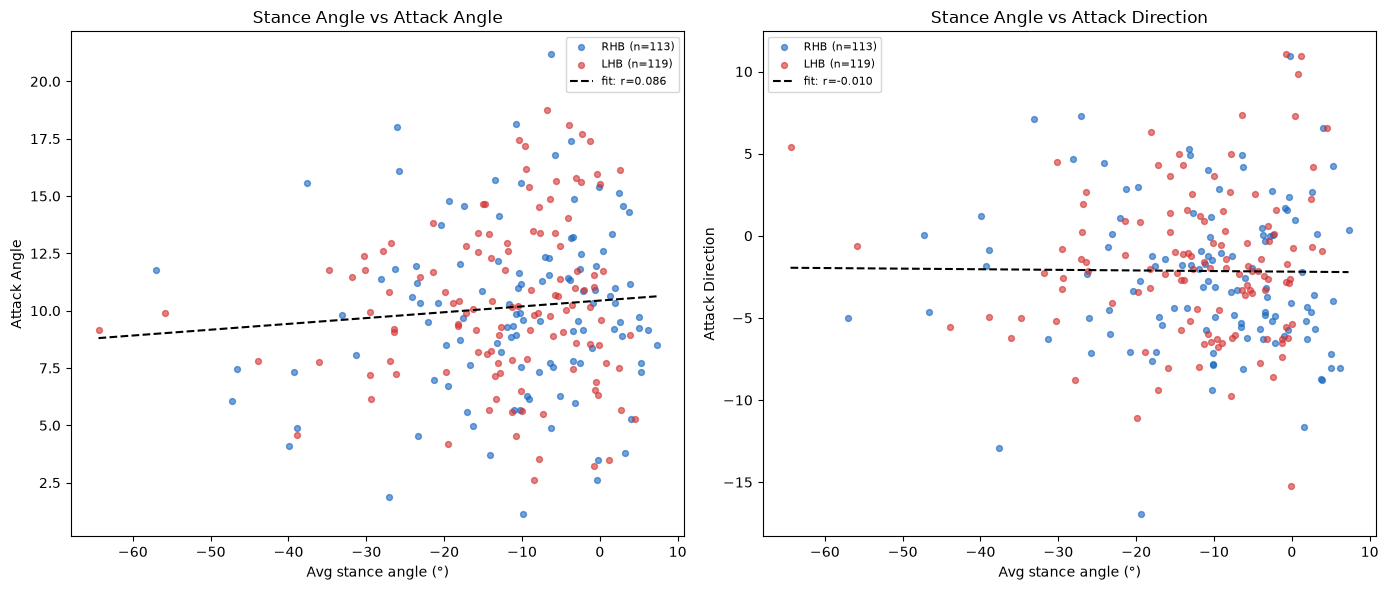

In [1]:
import pandas as pd
from scipy import stats
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt
import numpy as np

sp = pd.read_csv("bat-tracking-swing-path.csv")
st = pd.read_csv("batting-stance.csv")

# ── Join on MLBAM player id — far more reliable than name matching ──────────
merged = sp.merge(
    st[["id", "bat_side", "avg_foot_sep", "avg_stance_angle"]],
    on="id", how="inner"
)
print(f"Swing-path rows: {len(sp)}   Stance rows: {len(st)}   "
      f"Matched on id: {len(merged)}")

unmatched = set(st["id"]) - set(sp["id"])
if unmatched:
    print(f"{len(unmatched)} stance players not in swing-path file (below the "
          f"swing-path leaderboard's min-swings threshold, most likely)")

# ── Correlations: stance angle vs attack angle / attack direction ───────────
for target in ["attack_angle", "attack_direction"]:
    r, p = pearsonr(merged["avg_stance_angle"], merged[target])
    rho, p_s = spearmanr(merged["avg_stance_angle"], merged[target])
    print(f"\nStance angle vs {target}:")
    print(f"  Pearson r = {r:.3f}  (p={p:.2e})")
    print(f"  Spearman ρ = {rho:.3f}  (p={p_s:.2e})")

# ── Same, split by handedness — stance angle sign convention likely differs ──
# by bat side the same way spray angle did earlier in this session, so check
# empirically rather than assuming a shared sign.
print("\n── By handedness ──")
for side in merged["bat_side"].dropna().unique():
    sub = merged[merged["bat_side"] == side]
    if len(sub) < 15:
        continue
    for target in ["attack_angle", "attack_direction"]:
        r, p = pearsonr(sub["avg_stance_angle"], sub[target])
        print(f"  {side}HB (n={len(sub)}): stance vs {target}  r={r:+.3f}  (p={p:.2e})")

# ── Visualize ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, target in zip(axes, ["attack_angle", "attack_direction"]):
    for side, color in zip(merged["bat_side"].dropna().unique(), ["#1565C0", "#D32F2F"]):
        sub = merged[merged["bat_side"] == side]
        ax.scatter(sub["avg_stance_angle"], sub[target], s=18, alpha=0.6,
                  color=color, label=f"{side}HB (n={len(sub)})")
    slope, intercept, r, *_ = stats.linregress(merged["avg_stance_angle"], merged[target])
    xs = np.linspace(merged["avg_stance_angle"].min(), merged["avg_stance_angle"].max(), 100)
    ax.plot(xs, intercept + slope * xs, "k--", linewidth=1.5, label=f"fit: r={r:.3f}")
    ax.set_xlabel("Avg stance angle (°)")
    ax.set_ylabel(target.replace("_", " ").title())
    ax.set_title(f"Stance Angle vs {target.replace('_', ' ').title()}")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Matched on id: 232

═══ avg_stance_angle ═══
  vs attack_angle:  Pearson r=+0.086 (p=1.89e-01)   Spearman ρ=+0.053 (p=4.22e-01)
  vs attack_direction:  Pearson r=-0.010 (p=8.80e-01)   Spearman ρ=-0.042 (p=5.21e-01)
  ── by handedness ──
    RHB (n=113): avg_stance_angle vs attack_angle  r=+0.077  (p=4.18e-01)
    RHB (n=113): avg_stance_angle vs attack_direction  r=-0.046  (p=6.27e-01)
    LHB (n=119): avg_stance_angle vs attack_angle  r=+0.103  (p=2.64e-01)
    LHB (n=119): avg_stance_angle vs attack_direction  r=+0.036  (p=6.94e-01)

═══ avg_foot_sep ═══
  vs attack_angle:  Pearson r=-0.018 (p=7.79e-01)   Spearman ρ=-0.046 (p=4.89e-01)
  vs attack_direction:  Pearson r=+0.045 (p=4.91e-01)   Spearman ρ=+0.039 (p=5.52e-01)
  ── by handedness ──
    RHB (n=113): avg_foot_sep vs attack_angle  r=+0.023  (p=8.11e-01)
    RHB (n=113): avg_foot_sep vs attack_direction  r=+0.031  (p=7.42e-01)
    LHB (n=119): avg_foot_sep vs attack_angle  r=-0.056  (p=5.43e-01)
    LHB (n=119): avg_foot_sep v

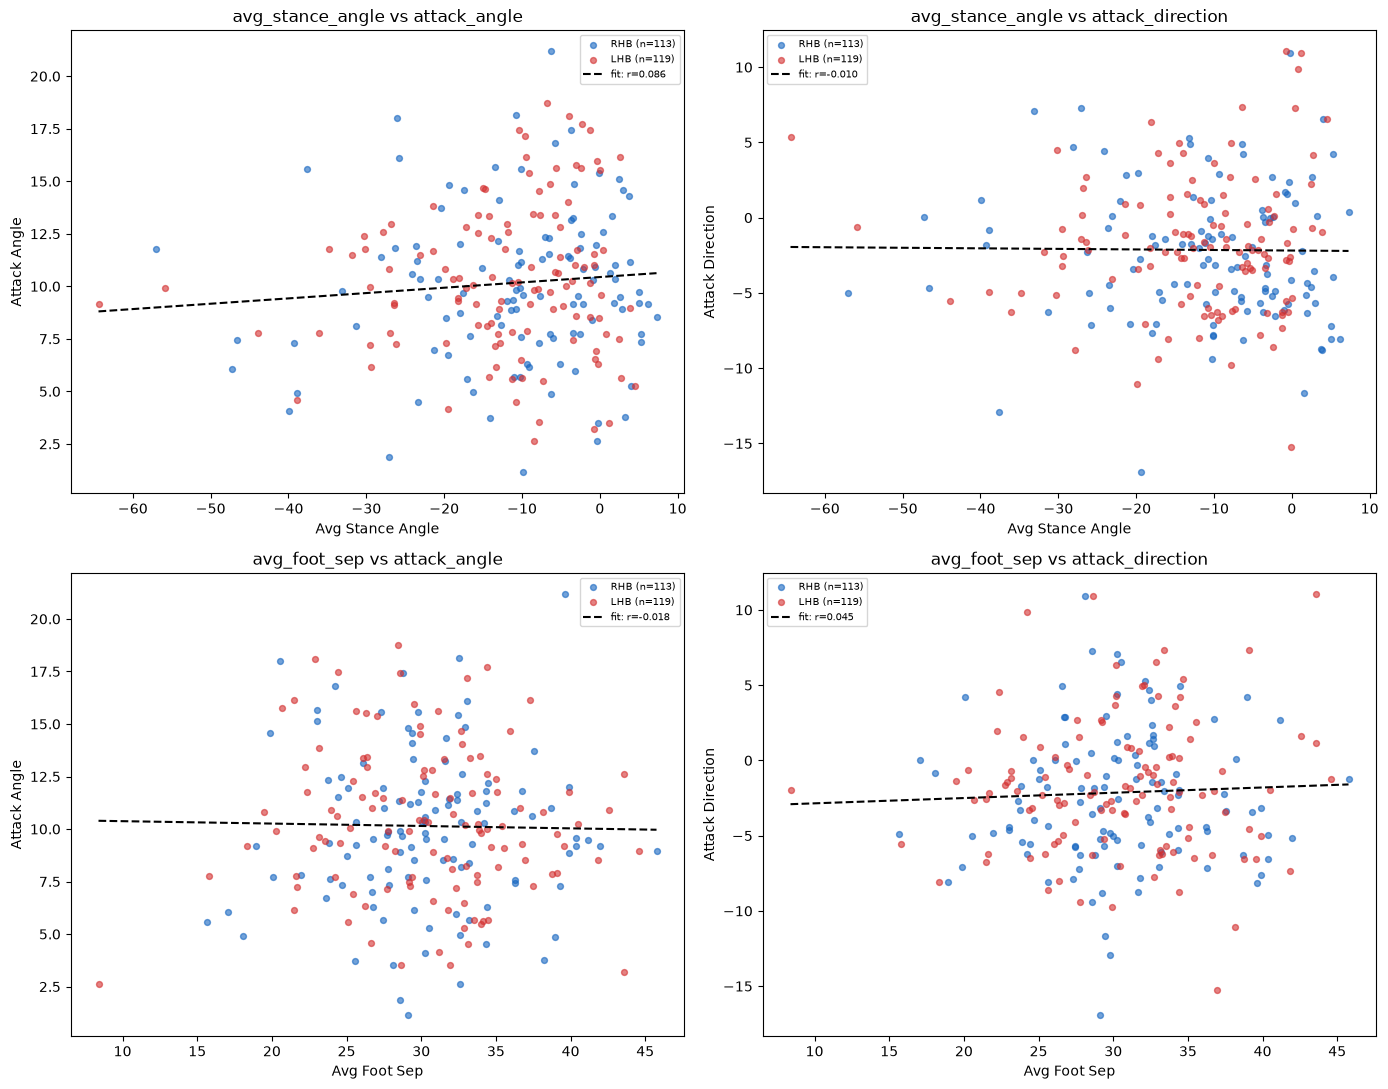

In [2]:
import pandas as pd
from scipy import stats
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt
import numpy as np

sp = pd.read_csv("bat-tracking-swing-path.csv")
st = pd.read_csv("batting-stance.csv")

merged = sp.merge(
    st[["id", "bat_side", "avg_foot_sep", "avg_stance_angle"]],
    on="id", how="inner"
)
print(f"Matched on id: {len(merged)}")

STANCE_METRICS = ["avg_stance_angle", "avg_foot_sep"]
TARGETS = ["attack_angle", "attack_direction"]

# ── Correlations ──────────────────────────────────────────────────────────────
for stance_metric in STANCE_METRICS:
    print(f"\n═══ {stance_metric} ═══")
    for target in TARGETS:
        r, p = pearsonr(merged[stance_metric], merged[target])
        rho, p_s = spearmanr(merged[stance_metric], merged[target])
        print(f"  vs {target}:  Pearson r={r:+.3f} (p={p:.2e})   "
              f"Spearman ρ={rho:+.3f} (p={p_s:.2e})")

    print("  ── by handedness ──")
    for side in merged["bat_side"].dropna().unique():
        sub = merged[merged["bat_side"] == side]
        if len(sub) < 15:
            continue
        for target in TARGETS:
            r, p = pearsonr(sub[stance_metric], sub[target])
            print(f"    {side}HB (n={len(sub)}): {stance_metric} vs {target}  "
                  f"r={r:+.3f}  (p={p:.2e})")

# ── Also check stance angle vs foot separation itself — are these two ────────
# stance metrics independent, or largely redundant with each other?
r_stance, p_stance = pearsonr(merged["avg_stance_angle"], merged["avg_foot_sep"])
print(f"\navg_stance_angle vs avg_foot_sep: r={r_stance:+.3f} (p={p_stance:.2e})")

# ── Visualize: 2 stance metrics × 2 targets = 4 panels ────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
colors = {"R": "#1565C0", "L": "#D32F2F"}

for row, stance_metric in enumerate(STANCE_METRICS):
    for col, target in enumerate(TARGETS):
        ax = axes[row, col]
        for side in merged["bat_side"].dropna().unique():
            sub = merged[merged["bat_side"] == side]
            ax.scatter(sub[stance_metric], sub[target], s=18, alpha=0.6,
                      color=colors.get(side, "gray"), label=f"{side}HB (n={len(sub)})")
        slope, intercept, r, *_ = stats.linregress(merged[stance_metric], merged[target])
        xs = np.linspace(merged[stance_metric].min(), merged[stance_metric].max(), 100)
        ax.plot(xs, intercept + slope * xs, "k--", linewidth=1.5, label=f"fit: r={r:.3f}")
        ax.set_xlabel(stance_metric.replace("_", " ").title())
        ax.set_ylabel(target.replace("_", " ").title())
        ax.set_title(f"{stance_metric} vs {target}")
        ax.legend(fontsize=7)

plt.tight_layout(); plt.show()


═══ attack_angle ═══
  Main effects only:        R² = 0.0086
  + interaction term:       R² = 0.0205   (gain: +0.0119)
  Interaction coefficient:  -0.0050
  Held-out R² — main only:  -0.0080
  Held-out R² — with interaction: -0.0090

═══ attack_direction ═══
  Main effects only:        R² = 0.0024
  + interaction term:       R² = 0.0054   (gain: +0.0030)
  Interaction coefficient:  +0.0032
  Held-out R² — main only:  -0.0799
  Held-out R² — with interaction: -0.0709


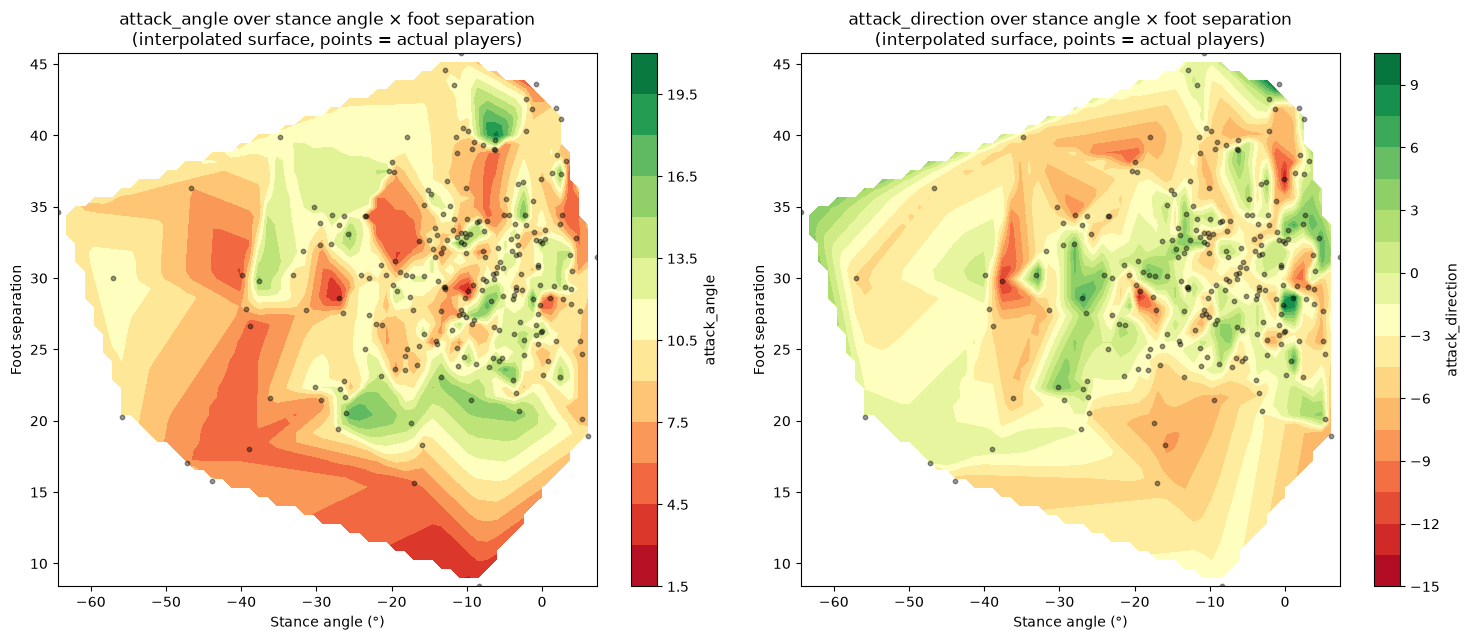

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

sp = pd.read_csv("bat-tracking-swing-path.csv")
st = pd.read_csv("batting-stance.csv")

merged = sp.merge(
    st[["id", "bat_side", "avg_foot_sep", "avg_stance_angle"]],
    on="id", how="inner"
)

# ── Regression with explicit interaction term ─────────────────────────────────
merged["stance_x_sep"] = merged["avg_stance_angle"] * merged["avg_foot_sep"]

for target in ["attack_angle", "attack_direction"]:
    X_main = merged[["avg_stance_angle", "avg_foot_sep"]].to_numpy(dtype=np.float64)
    X_int  = merged[["avg_stance_angle", "avg_foot_sep", "stance_x_sep"]].to_numpy(dtype=np.float64)
    y = merged[target].to_numpy(dtype=np.float64)

    r2_main = LinearRegression().fit(X_main, y).score(X_main, y)
    model_int = LinearRegression().fit(X_int, y)
    r2_int = model_int.score(X_int, y)

    print(f"\n═══ {target} ═══")
    print(f"  Main effects only:        R² = {r2_main:.4f}")
    print(f"  + interaction term:       R² = {r2_int:.4f}   (gain: {r2_int - r2_main:+.4f})")
    print(f"  Interaction coefficient:  {model_int.coef_[2]:+.4f}")

    # Held-out check before trusting the gain
    tr_idx, te_idx = train_test_split(np.arange(len(merged)), test_size=0.3, random_state=42)
    m_main = LinearRegression().fit(X_main[tr_idx], y[tr_idx])
    m_int  = LinearRegression().fit(X_int[tr_idx], y[tr_idx])
    r2_main_te = m_main.score(X_main[te_idx], y[te_idx])
    r2_int_te  = m_int.score(X_int[te_idx], y[te_idx])
    print(f"  Held-out R² — main only:  {r2_main_te:.4f}")
    print(f"  Held-out R² — with interaction: {r2_int_te:.4f}")

# ── Visual: 2D heatmap of each target over the stance-angle × foot-sep plane ──
from scipy.interpolate import griddata

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, target in zip(axes, ["attack_angle", "attack_direction"]):
    xi = np.linspace(merged["avg_stance_angle"].min(), merged["avg_stance_angle"].max(), 60)
    yi = np.linspace(merged["avg_foot_sep"].min(), merged["avg_foot_sep"].max(), 60)
    XI, YI = np.meshgrid(xi, yi)
    ZI = griddata(
        (merged["avg_stance_angle"], merged["avg_foot_sep"]), merged[target],
        (XI, YI), method="linear"
    )
    im = ax.contourf(XI, YI, ZI, levels=15, cmap="RdYlGn")
    ax.scatter(merged["avg_stance_angle"], merged["avg_foot_sep"], s=10,
              color="black", alpha=0.4)
    plt.colorbar(im, ax=ax, label=target)
    ax.set_xlabel("Stance angle (°)")
    ax.set_ylabel("Foot separation")
    ax.set_title(f"{target} over stance angle × foot separation\n(interpolated surface, points = actual players)")
plt.tight_layout(); plt.show()